# When Fraud Patterns Change
### Benchmarking drift adaptation methods for financial transactions

This notebook runs the experiments for my M.Sc. thesis. The question is simple: **when fraudsters change
their tactics, which way of updating a fraud model copes best?**

I compare four strategies on a stream of card transactions in which the fraud pattern changes at a month
I choose. Because I control the drift, I know exactly when it happened and can measure how long each
strategy needs to recover.

| Strategy | Idea | Type of adaptation |
|---|---|---|
| Static baseline | Random Forest trained once, never updated | none (reference) |
| Sliding window | Random Forest retrained every month on the latest months | blind |
| Detector-triggered | Random Forest retrained only when ADWIN/DDM raises a drift alarm | informed |
| Online learning | model updated after every labelled transaction | continuous |

All code lives in the `fraud_drift` package, so this notebook, the Streamlit app and `run_experiment.py`
give exactly the same numbers.

## 1. Setup and reproducibility

Every random step (data generation, Random Forest, Adaptive Random Forest) takes its seed from the config,
and every model runs single-threaded. Running this notebook again gives **the same numbers every time**.
The last section checks this with a fingerprint (a hash of all results).

In [1]:
import sys
from pathlib import Path
from dataclasses import replace

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraud_drift import (ExperimentConfig, PATTERNS, build_stream, run_experiment, summary_table,
                         results_fingerprint, environment_info, load_kaggle)
from fraud_drift.plotting import plot_metric, plot_costs, COLORS

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

cfg = ExperimentConfig.from_json(ROOT / "configs" / "default.json")
print("Seed:", cfg.seed)
print(environment_info())
cfg

Seed: 42
{'python': '3.13.16', 'platform': 'Linux-6.18.44-fc-v242-x86_64-with-glibc2.39', 'machine': 'x86_64', 'packages': {'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'river': '0.26.1', 'matplotlib': '3.11.2', 'streamlit': '1.67.0'}}


ExperimentConfig(per_month=5000, n_months=18, warmup_months=2, fraud_rate=0.05, drift_type='sudden', drift_month=6, transition_months=4, recur_month=12, n_trees=100, window=2, detector='adwin', adwin_delta=0.002, monitor='fraud_recall', online_model='logreg', threshold=0.5, label_delay=0, investigation_cost=15.0, retraining_cost=500.0, seed=42)

## 2. The data: a stream with a known change in fraud

Each month has the same number of transactions with five features: amount, hour of the day, number of
transactions in the last hour, foreign merchant (0/1) and new device (0/1).

Normal customers behave the same throughout. Only **what fraud looks like** changes:

In [2]:
for k, v in PATTERNS.items():
    print(f"Pattern {k}: {v}")

Pattern A: old fraud pattern: large amounts, late at night (00:00-04:59)
Pattern B: new fraud pattern: small amounts, bursts of transactions, foreign merchant, new device


This is *real* concept drift: the link between the features and the label changes, P(fraud | features).
I simulate three kinds of change, following the taxonomy of Gama et al. (2014) and Lu et al. (2019):

- **sudden**: pattern A switches to pattern B from one month to the next
- **gradual**: pattern B takes over step by step over a few months
- **recurring**: pattern B appears, and later pattern A comes back

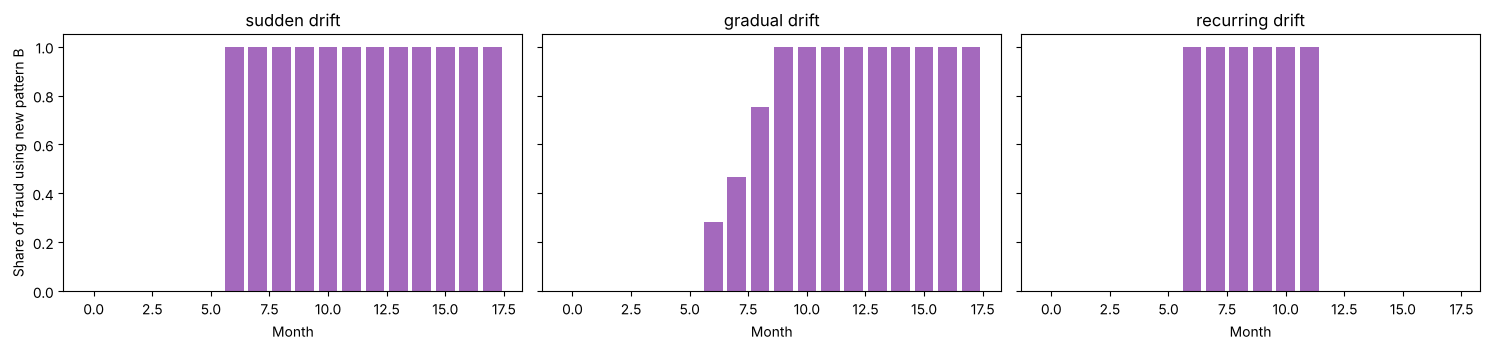

90,000 transactions, 4,500 frauds (5.0%)


,month,amount,hour,n_txn_1h,foreign,device_new,is_fraud,pattern
0,0,27.24,13,1,0,0,0,-
1,0,7.10,7,0,0,0,0,-
2,0,42.54,2,1,0,0,0,-
3,0,51.45,10,2,0,1,0,-
4,0,2.85,6,4,1,0,0,-


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, d in zip(axes, ["sudden", "gradual", "recurring"]):
    s = build_stream(replace(cfg, drift_type=d))
    share = s[s.is_fraud == 1].groupby("month")["pattern"].apply(lambda p: (p == "B").mean())
    ax.bar(share.index, share.values, color=COLORS["triggered"], alpha=0.8)
    ax.set_title(f"{d} drift")
    ax.set_xlabel("Month")
axes[0].set_ylabel("Share of fraud using new pattern B")
plt.tight_layout()
plt.show()

stream = build_stream(cfg)
print(f"{len(stream):,} transactions, {stream.is_fraud.sum():,} frauds ({stream.is_fraud.mean():.1%})")
stream.head()

In [4]:
# what an average fraud looks like before and after the drift (sudden)
fraud = stream[stream.is_fraud == 1]
fraud.assign(period=np.where(fraud.month < cfg.drift_month, "before drift", "after drift")) \
     .groupby("period")[["amount", "hour", "n_txn_1h", "foreign", "device_new"]].mean().round(2)

,amount,hour,n_txn_1h,foreign,device_new
period,,,,,
after drift,16.68,11.26,7.46,1.00,1.0
before drift,145.62,2.03,1.53,0.17,0.2


## 3. How the strategies are evaluated

- The first two months are historical, fully labelled data used for the first training (warm-up).
- From month 2 onward, each month is scored **before** the model sees its labels (no peeking).
- **ROC-AUC** and **PR-AUC** measure ranking quality. PR-AUC is more honest when fraud is rare
  (Dal Pozzolo et al., 2014; He & Garcia, 2009).
- **F1** uses a fixed alarm threshold of 0.5.
- **Recovery delay** = months after the drift until PR-AUC is back to 80% of the strategy's pre-drift level (a smaller tolerance would count normal month-to-month noise as a dip).
- The detector-triggered strategy uses ADWIN watching the confirmed fraud cases (section 9 explains why).
- **Cost (EUR)** = value of missed fraud + 15 EUR per false alarm checked + 500 EUR per retraining.

## 4. Sudden drift

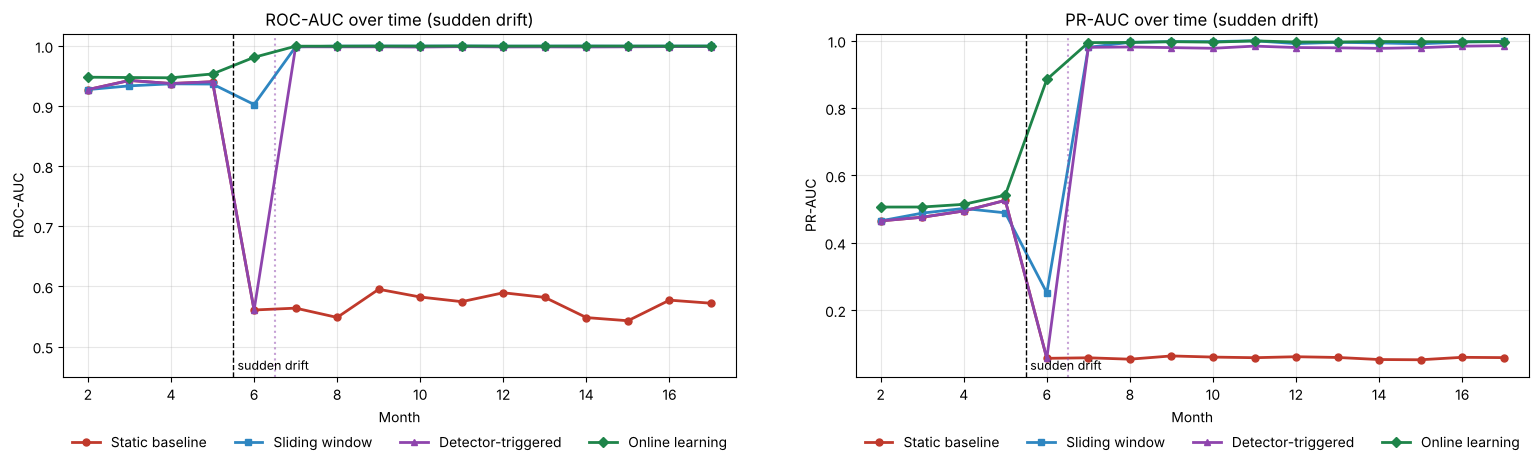

,Strategy,AUC before drift,AUC after drift,PR-AUC after drift,Recovery delay (months),F1,Retrainings,Missed frauds,False alarms,Missed fraud (EUR),Total cost (EUR)
0,Static baseline,0.937,0.570,0.058,not recovered,0.118,0,3543,1786,84662.57,111452.57
1,Sliding window,0.934,0.992,0.932,1,0.786,16,840,703,42828.12,61373.12
2,Detector-triggered,0.937,0.962,0.904,1,0.720,1,881,1256,41665.80,61005.80
3,Online learning,0.949,0.998,0.987,0,0.794,continuous,963,181,65112.78,67827.78


In [5]:
results = {}
summaries = {}
for d in ["sudden", "gradual", "recurring"]:
    c = replace(cfg, drift_type=d)
    results[d] = run_experiment(c)
    summaries[d] = summary_table(results[d], c)

c = replace(cfg, drift_type="sudden")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
plot_metric(results["sudden"], c, "auc", ax=axes[0])
plot_metric(results["sudden"], c, "pr_auc", ax=axes[1])
plt.tight_layout(); plt.show()
summaries["sudden"]

**What happens.** The static model collapses at the drift and never comes back: it keeps looking for
large night-time payments while the fraudsters have moved to small, rapid foreign payments. The adaptive
strategies all recover; the differences are in *how fast* and *at what price* (number of retrainings,
false alarms).

## 5. Gradual drift

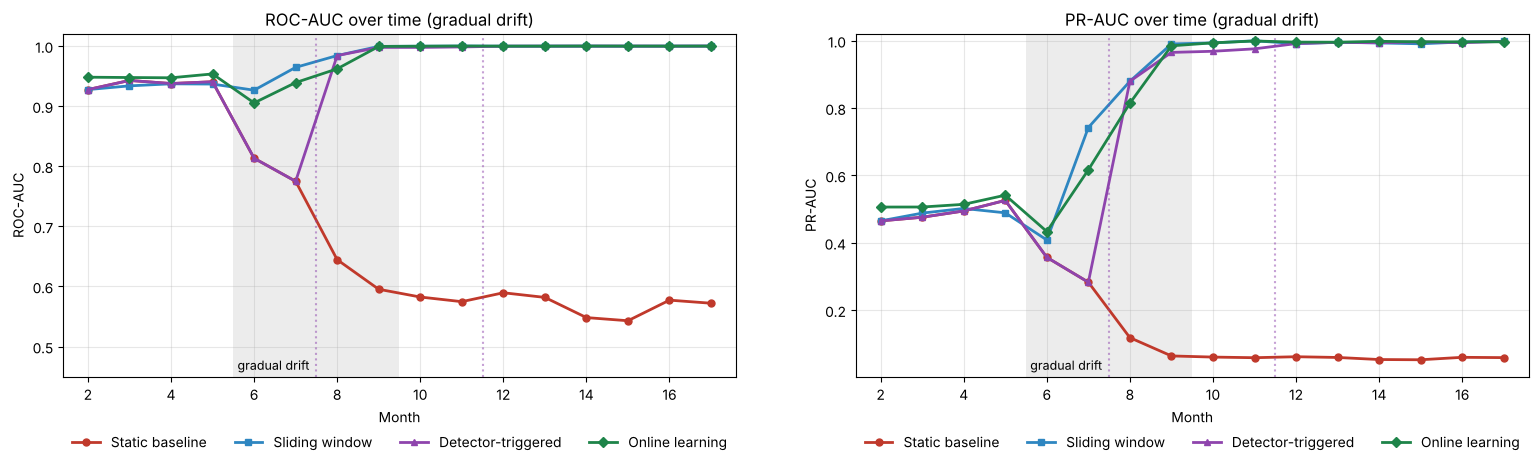

,Strategy,AUC before drift,AUC after drift,PR-AUC after drift,Recovery delay (months),F1,Retrainings,Missed frauds,False alarms,Missed fraud (EUR),Total cost (EUR)
0,Static baseline,0.937,0.616,0.107,not recovered,0.171,0,3365,1786,91093.43,117883.43
1,Sliding window,0.934,0.989,0.915,0,0.775,16,876,871,54108.18,75173.18
2,Detector-triggered,0.937,0.964,0.867,2,0.735,2,989,1049,53983.53,70718.53
3,Online learning,0.949,0.984,0.902,0,0.724,continuous,1306,238,94228.53,97798.53


In [6]:
c = replace(cfg, drift_type="gradual")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
plot_metric(results["gradual"], c, "auc", ax=axes[0])
plot_metric(results["gradual"], c, "pr_auc", ax=axes[1])
plt.tight_layout(); plt.show()
summaries["gradual"]

Gradual drift is harder for a drift detector: the error rate rises slowly, so the alarm comes later
than with sudden drift. Strategies that adapt all the time (sliding window, online learning) do not need
to notice the change first.

## 6. Recurring drift

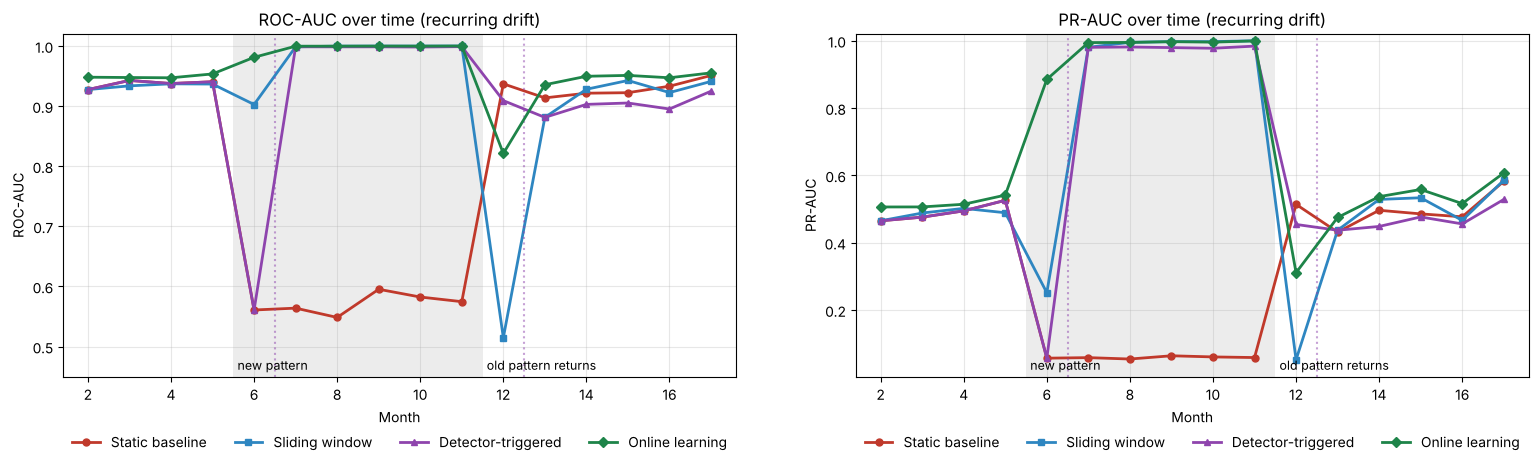

,Strategy,AUC before drift,AUC after drift,PR-AUC after drift,Recovery delay (months),Recovery after old pattern returns,F1,Retrainings,Missed frauds,False alarms,Missed fraud (EUR),Total cost (EUR)
0,Static baseline,0.937,0.750,0.278,not recovered,0,0.293,0,2886,1786,116438.10,143228.10
1,Sliding window,0.934,0.919,0.652,1,1,0.568,16,1772,1149,125921.12,151156.12
2,Detector-triggered,0.937,0.914,0.647,1,0,0.550,2,1840,1245,122766.98,142441.98
3,Online learning,0.949,0.962,0.739,0,1,0.567,continuous,2036,291,150926.80,155291.80


In [7]:
c = replace(cfg, drift_type="recurring")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
plot_metric(results["recurring"], c, "auc", ax=axes[0])
plot_metric(results["recurring"], c, "pr_auc", ax=axes[1])
plt.tight_layout(); plt.show()
summaries["recurring"]

Here the old pattern returns. A model that has completely "forgotten" pattern A has to adapt a second time,
which is the stability-plasticity trade-off discussed in the literature review.

## 7. Costs

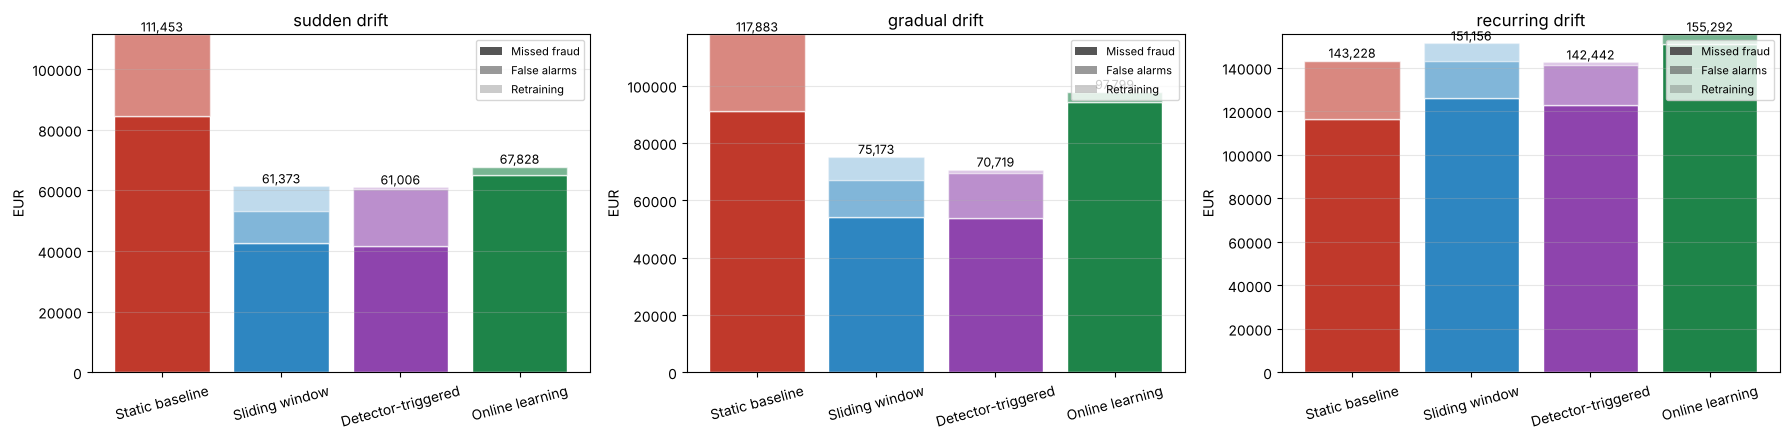

sudden                                                 gradual                                               recurring                                          
                   Missed frauds False alarms Retrainings Total cost (EUR) Missed frauds False alarms Retrainings Total cost (EUR) Missed frauds False alarms Retrainings Total cost (EUR)
Strategy                                                                                                                                                                                  
Static baseline             3543         1786           0        111452.57          3365         1786           0        117883.43          2886         1786           0        143228.10
Sliding window               840          703          16         61373.12           876          871          16         75173.18          1772         1149          16        151156.12
Detector-triggered           881         1256           1         61005.80           989         1049           2         70718.53          1840         1245           2        142441.98
Online learning              963          181  continuous         67827.78          1306          238  continuous         97798.53          2036          291  continuous        155291.80

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, d in zip(axes, ["sudden", "gradual", "recurring"]):
    plot_costs(results[d], ax=ax, title=f"{d} drift")
    ax.tick_params(axis="x", labelrotation=15)
plt.tight_layout(); plt.show()

pd.concat({d: s.set_index("Strategy")[["Missed frauds", "False alarms", "Retrainings", "Total cost (EUR)"]]
           for d, s in summaries.items()}, axis=1)

## 8. Label delay

In practice a fraud is confirmed only when the customer disputes the payment, often weeks later
(Dal Pozzolo et al., 2018). Here I repeat the sudden-drift experiment with labels arriving 0, 1 and 2
months late.

In [9]:
rows = []
for delay in [0, 1, 2]:
    c = replace(cfg, drift_type="sudden", label_delay=delay)
    s = summary_table(run_experiment(c), c)
    s.insert(0, "Label delay (months)", delay)
    rows.append(s[["Label delay (months)", "Strategy", "PR-AUC after drift", "Recovery delay (months)", "Total cost (EUR)"]])
delay_table = pd.concat(rows, ignore_index=True)
delay_table.pivot(index="Strategy", columns="Label delay (months)", values=["PR-AUC after drift", "Recovery delay (months)"])

PR-AUC after drift               Recovery delay (months)                              
Label delay (months)                  0      1      2                       0              1              2
Strategy                                                                                                   
Detector-triggered                0.904  0.838  0.758                       1              2              3
Online learning                   0.987   0.84  0.762                       0              2              3
Sliding window                    0.932  0.856  0.777                       1              2              3
Static baseline                   0.058  0.058  0.058           not recovered  not recovered  not recovered

## 9. What should the drift detector watch?

A detector needs a signal. The textbook choice is the model's overall error rate (Gama et al., 2004;
Bifet & Gavaldà, 2007). With only 5% fraud, though, a model that misses every new fraud still gets about
95% of transactions right, so the overall error rate barely moves. Watching only the confirmed fraud cases
(was each one caught or missed?) is a recall signal, similar in spirit to class-imbalance-aware detectors.
I compare both signals, with ADWIN and DDM, on a smaller stream where the difference is clearer.

In [10]:
rows = []
for det in ["adwin", "ddm"]:
    for mon in ["fraud_recall", "error_rate"]:
        for d in ["sudden", "gradual"]:
            c = replace(cfg, drift_type=d, detector=det, monitor=mon, per_month=1500)
            r = run_experiment(c, strategies=["triggered"])["triggered"]
            post = r.monthly[r.monthly.month >= c.drift_month]
            rows.append({"Detector": det.upper(), "Watches": mon, "Drift": d,
                         "First alarm (months after drift)": (min(r.alarms) - c.drift_month) if r.alarms else None,
                         "Alarms": len(r.alarms), "PR-AUC after drift": round(post.pr_auc.mean(), 3)})
pd.DataFrame(rows)

,Detector,Watches,Drift,First alarm (months after drift),Alarms,PR-AUC after drift
0,ADWIN,fraud_recall,sudden,1,1,0.839
1,ADWIN,fraud_recall,gradual,3,1,0.733
2,ADWIN,error_rate,sudden,5,1,0.532
3,ADWIN,error_rate,gradual,5,1,0.582
4,DDM,fraud_recall,sudden,0,1,0.901
5,DDM,fraud_recall,gradual,2,1,0.806
6,DDM,error_rate,sudden,1,10,0.840
7,DDM,error_rate,gradual,4,7,0.659


## 10. Are the differences stable? (10 seeds)

One run with one seed could be lucky. I repeat the sudden-drift benchmark with 10 different seeds
(smaller stream to keep it quick) and report the mean and standard deviation. The seeds are fixed
(0-9), so this table is also reproducible.

In [11]:
rows = []
for s in range(10):
    c = replace(cfg, drift_type="sudden", per_month=2000, seed=s)
    t = summary_table(run_experiment(c), c)
    t["seed"] = s
    rows.append(t)
seeds = pd.concat(rows, ignore_index=True)
seeds.groupby("Strategy", sort=False)[["AUC after drift", "PR-AUC after drift", "Total cost (EUR)"]] \
     .agg(["mean", "std"]).round(3)

AUC after drift        PR-AUC after drift        Total cost (EUR)          
                              mean    std               mean    std             mean       std
Strategy                                                                                      
Static baseline              0.614  0.102              0.081  0.045        43682.283  1740.398
Sliding window               0.961  0.004              0.917  0.002        28721.234  1359.274
Detector-triggered           0.966  0.009              0.900  0.007        25007.884  1709.833
Online learning              0.996  0.001              0.981  0.002        28288.648  1507.403

## 11. Realism check on the Kaggle credit-card data (optional)

The ULB credit-card dataset (284,807 transactions, 492 frauds) is not in the repository. Download
`creditcard.csv` from Kaggle and place it in the `data/` folder; this cell will then run automatically.
There is no injected drift here: the goal is to check that the strategies behave sensibly on real data.

In [12]:
kaggle_path = ROOT / "data" / "creditcard.csv"
if kaggle_path.exists():
    real, feats = load_kaggle(kaggle_path, n_months=12)
    ck = replace(cfg, drift_type="none", n_months=12)
    real_results = run_experiment(ck, stream=real, features=feats)
    plot_metric(real_results, ck, "pr_auc", title="Kaggle data: PR-AUC per time slice")
    plt.show()
    display(summary_table(real_results, ck))
else:
    print("data/creditcard.csv not found - skipping (see README).")

data/creditcard.csv not found - skipping (see README).


## 12. Reproducibility check

The fingerprint is a hash of every monthly number. If it matches the one saved by
`python run_experiment.py` in `results/`, the run is identical.

In [13]:
import json
for d in ["sudden", "gradual", "recurring"]:
    fp = results_fingerprint(results[d])
    info_file = ROOT / "results" / d / "run_info.json"
    saved = json.loads(info_file.read_text())["fingerprint"] if info_file.exists() else "no saved run"
    print(f"{d:<10} this run: {fp}   saved: {saved}   {'✔ identical' if fp == saved else ''}")

sudden     this run: e86eefc13a1e335b   saved: e86eefc13a1e335b   ✔ identical
gradual    this run: ba3ec70b64ae29d3   saved: ba3ec70b64ae29d3   ✔ identical
recurring  this run: b64949d3e5205776   saved: b64949d3e5205776   ✔ identical
